In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [2]:
from google.colab import files

uploaded = files.upload()

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv


In [3]:
nama_file = list(uploaded.keys())[0]

df = pd.read_csv(nama_file)

print(df.head())
print(df.info())

   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_calls_made  
0                  1                    1                 0  
1                  0                   10                 9  
2                  1                    3                 4  
3                  1                    1                 4  
4                  0                   12                 3  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    i

In [4]:
print("Ukuran dataset:", df.shape)

print("Nama kolom:")
print(df.columns.tolist())

print("Data kosong:")
print(df.isnull().sum())

Ukuran dataset: (660, 7)
Nama kolom:
['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
Data kosong:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


In [5]:
# Menghapus kolom identitas
df_model = df.drop(columns=['Sl_No', 'Customer Key'])

# Memeriksa data
print(df_model.head())

print("Ukuran data:", df_model.shape)

   Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  \
0            100000                   2                  1   
1             50000                   3                  0   
2             50000                   7                  1   
3             30000                   5                  1   
4            100000                   6                  0   

   Total_visits_online  Total_calls_made  
0                    1                 0  
1                   10                 9  
2                    3                 4  
3                    1                 4  
4                   12                 3  
Ukuran data: (660, 5)


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df_model)

print("Hasil normalisasi:")
print(X_scaled[:5])

Hasil normalisasi:
[[ 1.74018685 -1.24922476 -0.86045063 -0.54748969 -1.25153737]
 [ 0.41029254 -0.78758515 -1.47373077  2.5205186   1.89185881]
 [ 0.41029254  1.05897329 -0.86045063  0.13428993  0.1455276 ]
 [-0.12166518  0.13569407 -0.86045063 -0.54748969  0.1455276 ]
 [ 1.74018685  0.59733368 -1.47373077  3.20229822 -0.20373864]]


In [7]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

    print(f"Jumlah cluster: {k}, Silhouette Score: {score:.4f}")

Jumlah cluster: 2, Silhouette Score: 0.4177
Jumlah cluster: 3, Silhouette Score: 0.5148
Jumlah cluster: 4, Silhouette Score: 0.3481
Jumlah cluster: 5, Silhouette Score: 0.2569
Jumlah cluster: 6, Silhouette Score: 0.2268
Jumlah cluster: 7, Silhouette Score: 0.2163
Jumlah cluster: 8, Silhouette Score: 0.2187
Jumlah cluster: 9, Silhouette Score: 0.1953
Jumlah cluster: 10, Silhouette Score: 0.1931


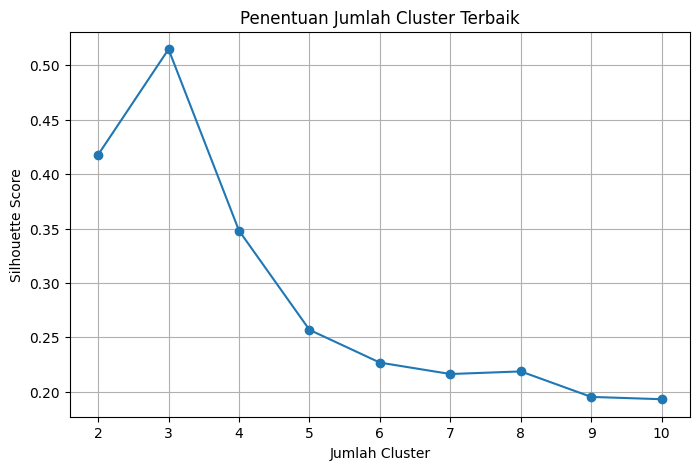

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.xlabel('Jumlah Cluster')
plt.ylabel('Silhouette Score')
plt.title('Penentuan Jumlah Cluster Terbaik')
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [9]:
best_k = range(2, 11)[np.argmax(silhouette_scores)]

print("Jumlah cluster terbaik:", best_k)

model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage='ward'
)

df_model['Cluster'] = model.fit_predict(X_scaled)

print(df_model.head())

Jumlah cluster terbaik: 3
   Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  \
0            100000                   2                  1   
1             50000                   3                  0   
2             50000                   7                  1   
3             30000                   5                  1   
4            100000                   6                  0   

   Total_visits_online  Total_calls_made  Cluster  
0                    1                 0        0  
1                   10                 9        1  
2                    3                 4        0  
3                    1                 4        0  
4                   12                 3        2  


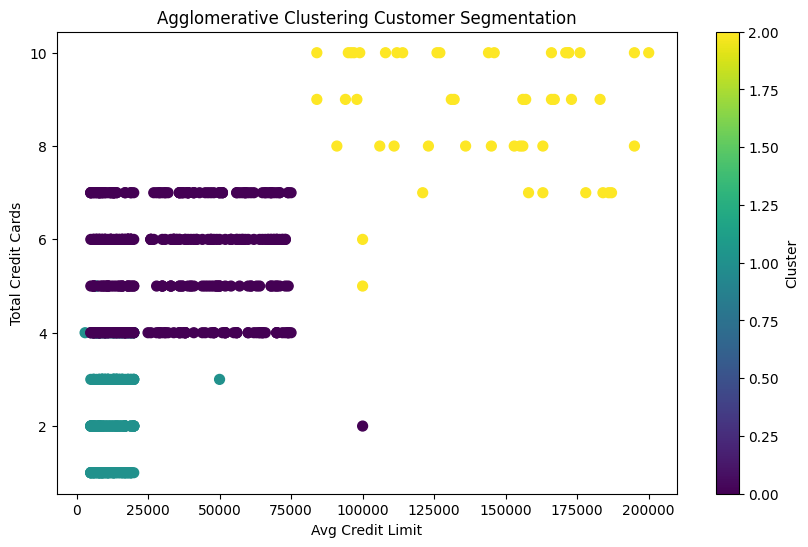

In [10]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_model['Avg_Credit_Limit'],
    df_model['Total_Credit_Cards'],
    c=df_model['Cluster'],
    cmap='viridis',
    s=50
)

plt.xlabel('Avg Credit Limit')
plt.ylabel('Total Credit Cards')

plt.title('Agglomerative Clustering Customer Segmentation')

plt.colorbar(label='Cluster')

plt.show()

In [11]:
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

labels = df_model['Cluster']

silhouette = silhouette_score(X_scaled, labels)

dbi = davies_bouldin_score(X_scaled, labels)

print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Index:", round(dbi, 4))

Silhouette Score: 0.5148
Davies-Bouldin Index: 0.681


In [12]:
print("Jumlah pelanggan setiap cluster:")
print(df_model['Cluster'].value_counts().sort_index())

print("\nJumlah cluster:")
print(df_model['Cluster'].nunique())

Jumlah pelanggan setiap cluster:
Cluster
0    385
1    225
2     50
Name: count, dtype: int64

Jumlah cluster:
3
